In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Dense, Input, Dropout, GlobalAveragePooling1D
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import imdb
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [20]:
# Parâmetros
max_features = 10000   # tamanho do vocabulário
maxlen = 200           # comprimento máximo das sequências

# Carregando o dataset IMDB
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_features)

/home/anderson/miniconda3/envs/intelligent_systems/lib/python3.11/site-packages/numpy/lib/_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


In [21]:
# Padronizando o comprimento das sequências

x_train = pad_sequences(x_train, maxlen=maxlen, padding='post', truncating='post')
x_test = pad_sequences(x_test, maxlen=maxlen, padding='post', truncating='post')

In [22]:
# Construção do modelo:
model = Sequential([
    Input(shape=(maxlen,)),
    Embedding(input_dim=max_features, output_dim=128),
    GlobalAveragePooling1D(),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

In [23]:
# Compilação
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,284,161 (4.90 MB)

 Trainable params: 1,284,161 (4.90 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# EarlyStopping para evitar overfitting e restaurar os melhores pesos encontrados
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Treinamento do modelo
history = model.fit(
    x_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/15


I0000 00:00:1794497387.990199   88491 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_41535__.12


298/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6205 - loss: 0.6424

I0000 00:00:1794497389.714174   88495 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_41535__.12


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7147 - loss: 0.5532 - val_accuracy: 0.8502 - val_loss: 0.3756
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8713 - loss: 0.3173 - val_accuracy: 0.8708 - val_loss: 0.3154
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8983 - loss: 0.2577 - val_accuracy: 0.8766 - val_loss: 0.3098
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9171 - loss: 0.2215 - val_accuracy: 0.8720 - val_loss: 0.3214
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9273 - loss: 0.1966 - val_accuracy: 0.8746 - val_loss: 0.3266
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9405 - loss: 0.1699 - val_accuracy: 0.8634 - val_loss: 0.3651
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9470 - loss: 0.1566 - val_accuracy: 0.8684 - val_loss: 0.3634
Epoch 8/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9569 - loss: 0.1332 - val_accuracy: 0.8642 - val_

In [25]:
# Avaliação final no conjunto de teste
loss, accuracy = model.evaluate(x_test, y_test)
print(f"\nAcurácia final no teste: {accuracy * 100:.2f}%")
print(f"Loss final no teste: {loss:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8594 - loss: 0.3353

Acurácia final no teste: 85.94%
Loss final no teste: 0.3353


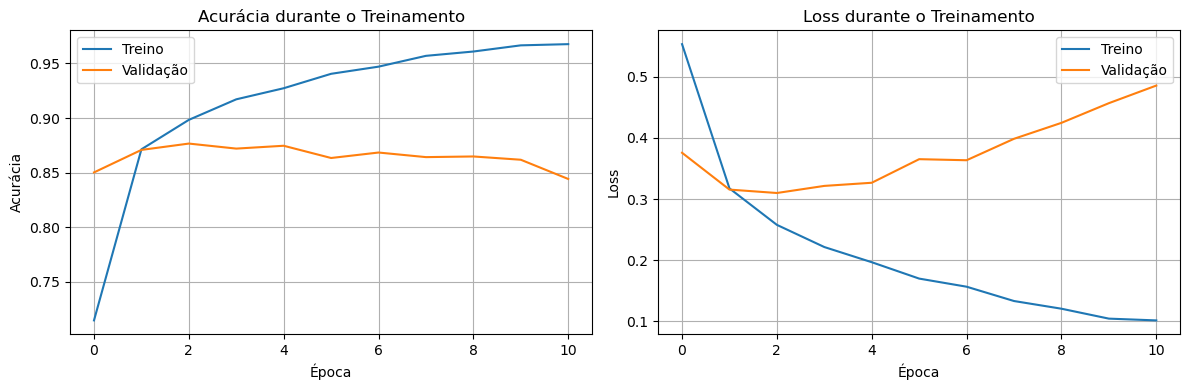

In [26]:
# Visualização da evolução do treino e validação
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title('Acurácia durante o Treinamento')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.title('Loss durante o Treinamento')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
MATRIZ DE CONFUSÃO (Numérica):
[[11132  1368]
 [ 2146 10354]]

RELATÓRIO DE CLASSIFICAÇÃO:
              precision    recall  f1-score   support

    Negativo       0.84      0.89      0.86     12500
    Positivo       0.88      0.83      0.85     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



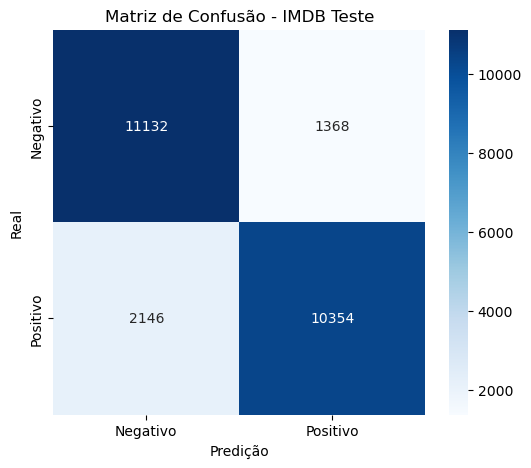

In [27]:
# Predições no conjunto de teste
y_pred_probs = model.predict(x_test)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# Matriz de Confusão em texto e Relatório Completo
labels = ['Negativo', 'Positivo']
cm = confusion_matrix(y_test, y_pred)

print("=" * 40)
print("MATRIZ DE CONFUSÃO (Numérica):")
print(cm)
print("=" * 40)
print("\nRELATÓRIO DE CLASSIFICAÇÃO:")
print(classification_report(y_test, y_pred, target_names=labels))

# Plot visual da Matriz de Confusão
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Matriz de Confusão - IMDB Teste')
plt.xlabel('Predição')
plt.ylabel('Real')
plt.show()